In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
%load_ext autoreload
%autoreload 2

from fwh_analysis import FWHDataset, FWHPlotter

In [22]:
def p_element_plot(dataframe, title=None):
    norm = mcolors.LogNorm(vmin = 1e-3, vmax=1e-1)
    cmap = cm.coolwarm

    fig, ax = plt.subplots(figsize=[8,6])
    color_val = cmap(norm(dataframe['error']))
    ax.scatter(dataframe['elements'] / 1000, dataframe['P'], color=color_val)

    sm = plt.cm.ScalarMappable(cmap = cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label("Log Error (%)")

    ax.set_xlabel(f"Element Count $(10^3)$")
    # ax.set_xscale('log')
    ax.set_ylabel("Temporal Resolution, P (Points Per Period)")
    ax.set_title(title)

    plt.show()

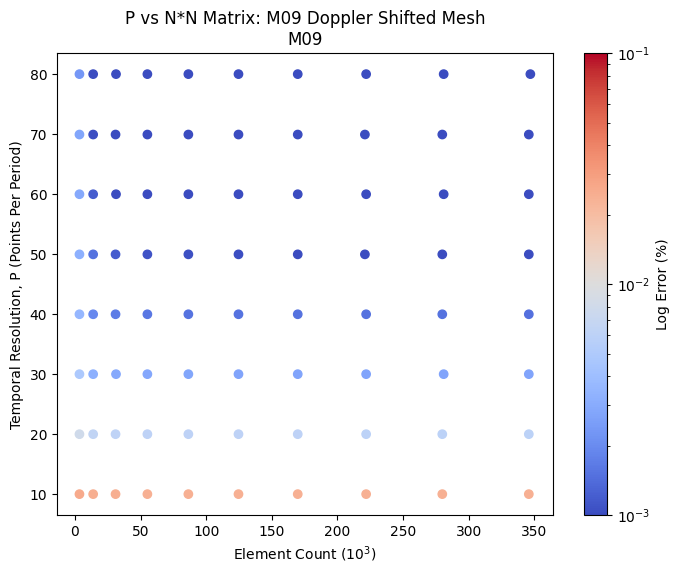

In [5]:
df_M09 = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260603/test_M09', use_doppler=True))
p_element_plot(df_M09,
               title='P vs N*N Matrix: M09 Doppler Shifted Mesh\nM09')

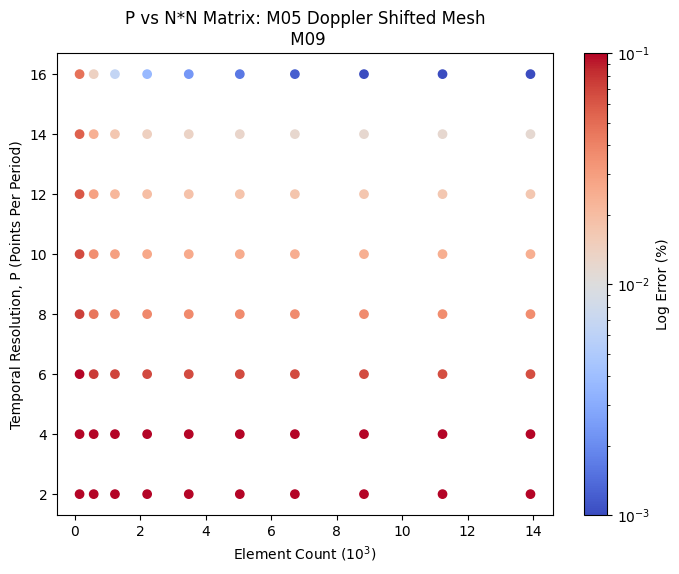

In [6]:
df_M0905 = pd.DataFrame(FWHDataset.compile_fwh_batch("data_260609/test_M09_M05_mesh"))
p_element_plot(df_M0905,
               title='P vs N*N Matrix: M05 Doppler Shifted Mesh\n M09')

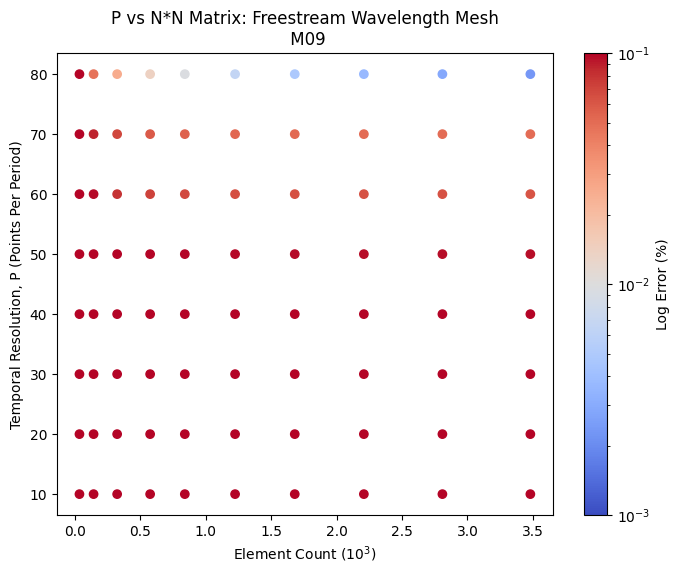

In [10]:
df_M09nd = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260609/test_M09_non_doppler_mesh', use_doppler=False))
p_element_plot(df_M09nd, 
               title='P vs N*N Matrix: Freestream Wavelength Mesh\n M09')

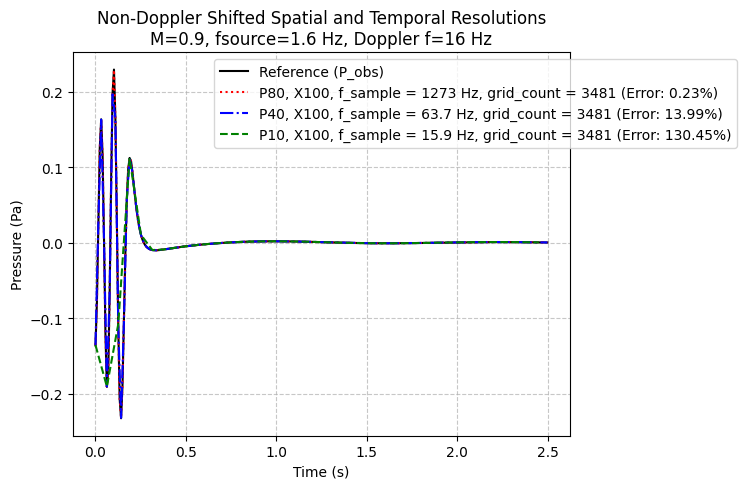

In [11]:
filepath = Path('data_260609/test_M09_non_doppler_mesh/')
ana = FWHDataset(filepath / 'ana_M90.dat')
p80_x100 = FWHDataset(filepath / 'P80_X100_M90.dat')
p40_x100 = FWHDataset(filepath / 'P40_X100_M90.dat')
p10_x100 = FWHDataset(filepath / 'P10_X100_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p40_x100, p10_x100, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P40, X100, f_sample = 63.7 Hz, grid_count = 3481',
    'P10, X100, f_sample = 15.9 Hz, grid_count = 3481'
],
title="Non-Doppler Shifted Spatial and Temporal Resolutions\nM=0.9, fsource=1.6 Hz, Doppler f=16 Hz")

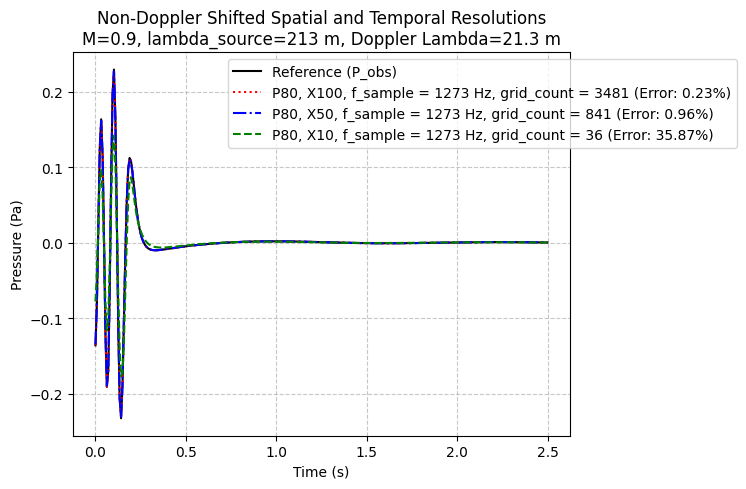

In [12]:
p80_x50 = FWHDataset(filepath / 'P80_X50_M90.dat')
p80_x10 = FWHDataset(filepath / 'P80_X10_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p80_x50, p80_x10, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P80, X50, f_sample = 1273 Hz, grid_count = 841',
    'P80, X10, f_sample = 1273 Hz, grid_count = 36'
], title="Non-Doppler Shifted Spatial and Temporal Resolutions\n" \
"M=0.9, lambda_source=213 m, Doppler Lambda=21.3 m"
)

In [40]:
folders = [
    'data_260609/multi_obs/obs_01',
    'data_260609/multi_obs/obs_02',
    'data_260609/multi_obs/obs_03',
    'data_260609/multi_obs/obs_04',
    'data_260609/multi_obs/obs_05',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=True))

df = pd.DataFrame(master)
obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
obs_05 = df[df['batch_name']=='obs_05']

In [46]:
obs_01['error'].mean()

np.float64(0.014213381072880477)

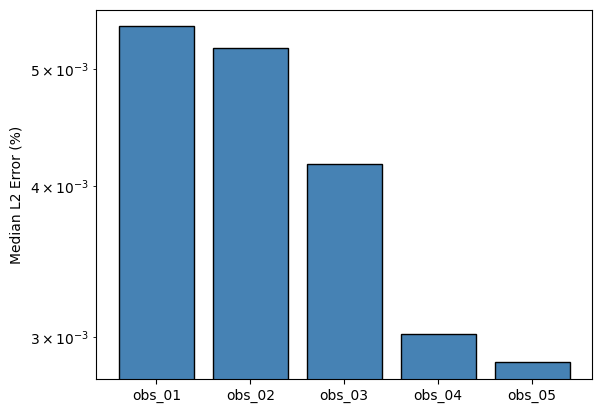

In [55]:
medians = [
    obs_01['error'].median(),
    obs_02['error'].median(),
    obs_03['error'].median(),
    obs_04['error'].median(),
    obs_05['error'].median(),
]

labels = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05']

fig, ax = plt.subplots()
ax.bar(labels, medians, edgecolor='black', color='steelblue')
ax.set_yscale('log')
ax.set_ylabel('Median L2 Error (%)')
ax.grid(True, axis='y', ls='--', alpha=0.5)

plt.show()

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))

# estimator=np.median calculates the central tendency
# errorbar='sd' draws the standard deviation lines to show variance across X and P
sns.barplot(data=df, x='batch_name', y='error', estimator=np.median, 
            errorbar='sd', palette='coolwarm', edgecolor='black', ax=ax)

ax.set_yscale('log')
ax.set_ylabel('Median L2 Error (%)')
ax.set_xlabel('Observer')
ax.set_title('Error Distribution Across Observer Arc')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

ModuleNotFoundError: No module named 'seaborn'

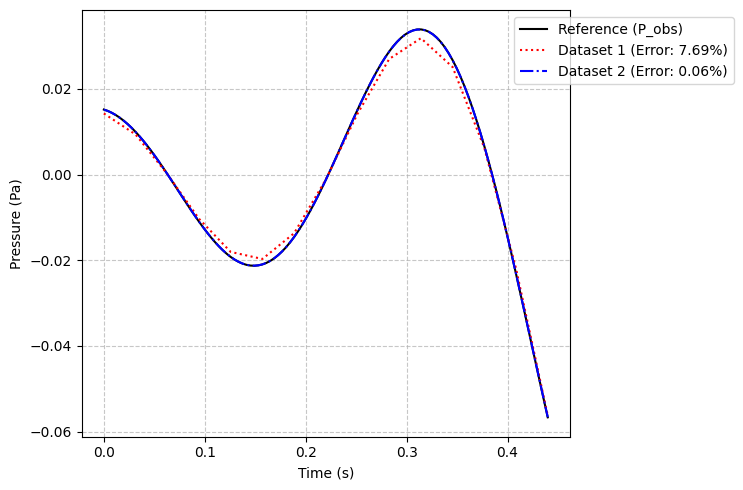

In [42]:
filepath = Path(f"{folders[0]}/")
ana = FWHDataset(filepath / "ana_M50.dat")
p10_x10 = FWHDataset(filepath / "P10_X10_M50.dat")
p80_x100 = FWHDataset(filepath / "P80_X100_M50.dat")
FWHPlotter.plot_pressure(ana, p10_x10, p80_x100, ref_col='P_obs')

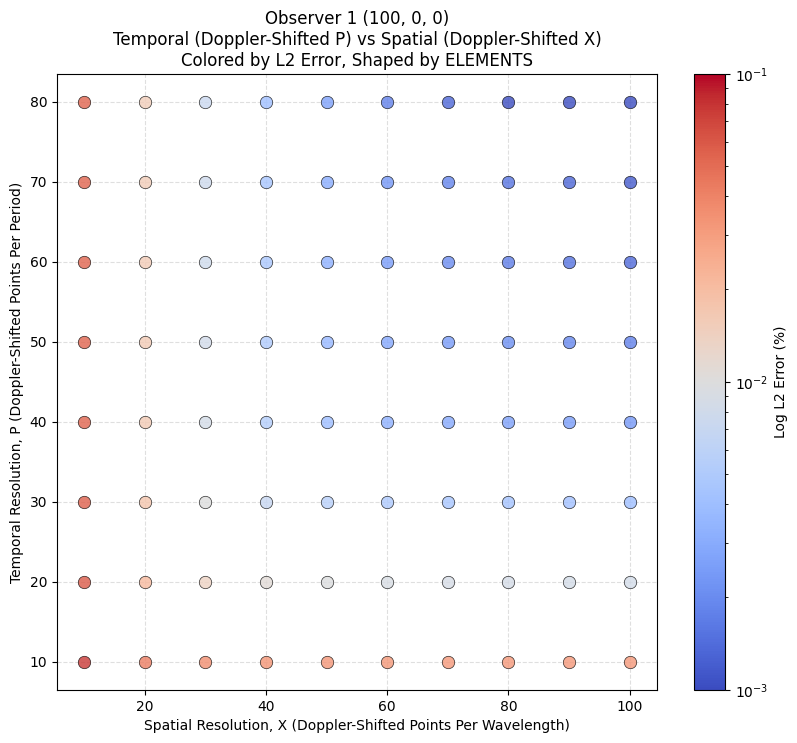

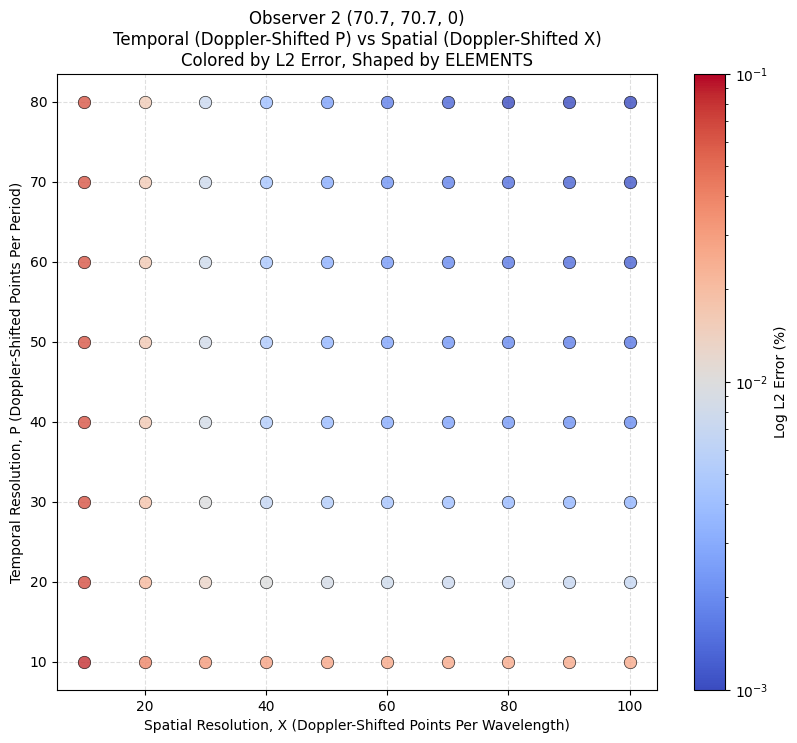

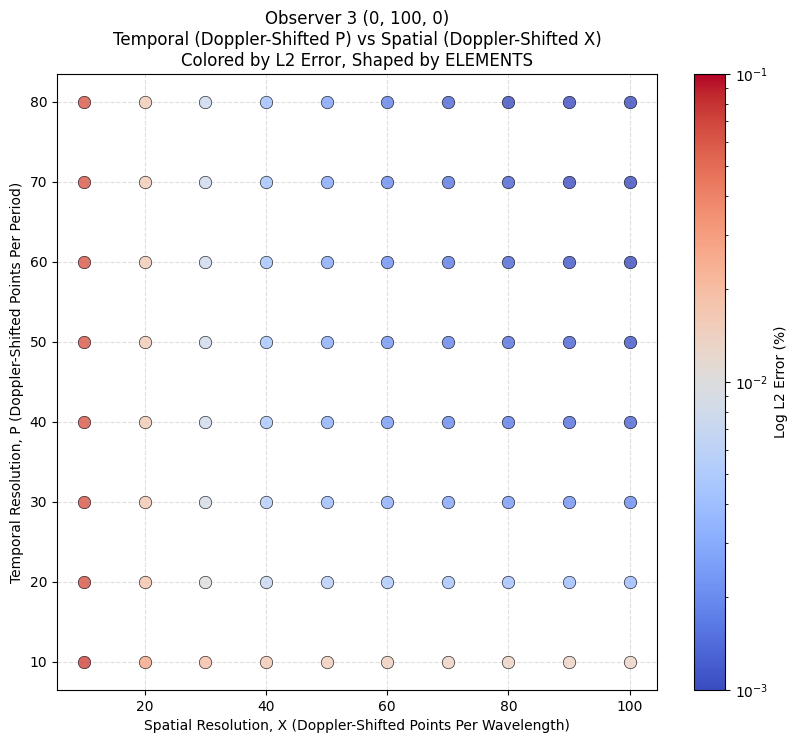

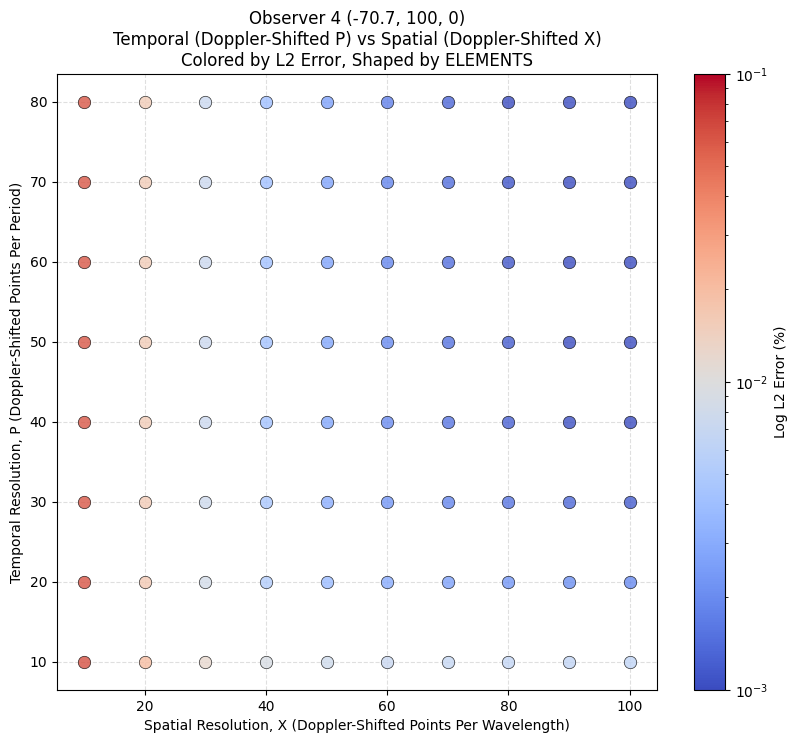

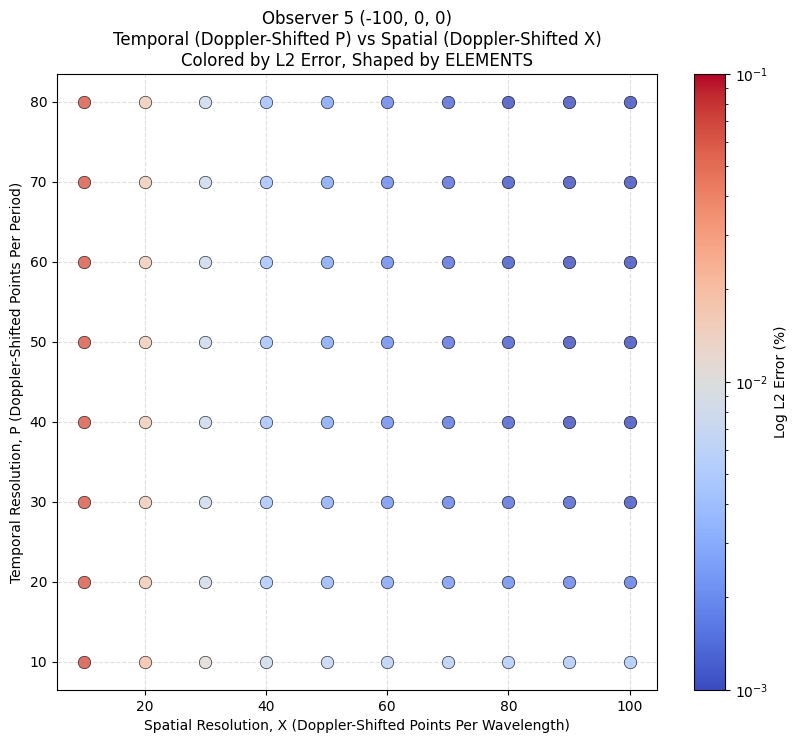

In [54]:
title = ['Observer 1 (100, 0, 0)', 
         'Observer 2 (70.7, 70.7, 0)', 
         'Observer 3 (0, 100, 0)', 
         'Observer 4 (-70.7, 100, 0)', 
         'Observer 5 (-100, 0, 0)']
for i,j in zip(folders, title):
    data = FWHDataset.compile_fwh_batch(Path(i), use_doppler=True)
    FWHPlotter.plot_px_parameter_space(data, legend=False, add_title=j)